# Đánh giá thử thách qua từng màn

Phân tích này tìm các màn có tỷ lệ không thắng cao hơn lân cận, sau đó đối chiếu khả năng đi tiếp và quay lại ngày sau để chọn nơi cần điều tra.

**Phạm vi.** Dữ liệu được tổng hợp cho màn 1–500. Bước sàng lọc sử dụng màn 8–500 có ít nhất 500 người bắt đầu.

**Phương pháp.** So sánh với trung vị lân cận, phát hiện bất thường bằng IQR, rồi kiểm tra chênh lệch hành trình theo nhóm người chơi. Các phép tính sử dụng bảng `analysis`; dữ liệu đầu vào nằm trong `data/`. Các file [SQL](sql/) được giữ để tham khảo bước tổng hợp.

**Kết quả.** Trong 298 màn đủ điều kiện, 19 màn vượt ngưỡng IQR và 3 màn thỏa toàn bộ điều kiện ưu tiên: 107, 109 và 144. Đây là danh sách ưu tiên điều tra từ dữ liệu quan sát.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from analysis_utils import load_data

Path("output").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

# Các ngưỡng cho phần phân tích trên dữ liệu tổng hợp.
MIN_USERS = 500
LOCAL_RADIUS = 4
IQR_MULTIPLIER = 1.5
BEHAVIOR_PERCENTILE = 0.10

level_summary = load_data("level_summary.csv")


## 1. Kiểm tra dữ liệu local

Bài sử dụng hai bảng CSV trong `data/`: bảng tổng hợp cho 500 màn và bảng so sánh hai nhóm người chơi ở màn 109. Mỗi dòng tương ứng một màn hoặc một nhóm người chơi.

Kiểm tra khóa màn, phạm vi và các cột đếm trước khi tính chỉ số.


In [2]:
assert level_summary["level_index"].is_unique
assert level_summary["level_index"].between(1, 500).all()
assert len(level_summary) == 500

count_columns = [
    "start_events",
    "start_users",
    "end_events",
    "end_users",
    "win_events",
    "non_win_events",
]
assert level_summary[count_columns].notna().all().all()
assert (level_summary[count_columns] >= 0).all().all()
assert (
    level_summary["win_events"] + level_summary["non_win_events"]
    == level_summary["end_events"]
).all()

display(
    pd.DataFrame(
        {
            "Số màn": [len(level_summary)],
            "Số cột đầu vào": [len(level_summary.columns)],
            "Màn có nhiều level_id": [(level_summary["level_variants"] > 1).sum()],
            "Màn đủ 500 người bắt đầu": [
                (level_summary["start_users"] >= MIN_USERS).sum()
            ],
        }
    )
)
display(level_summary[count_columns].isna().sum().rename("Số giá trị thiếu").to_frame())


,Số màn,Số cột đầu vào,Màn có nhiều level_id,Màn đủ 500 người bắt đầu
0,500,28,181,305


,Số giá trị thiếu
start_events,0
start_users,0
end_events,0
end_users,0
win_events,0
non_win_events,0


## 2. Chỉ số và quy tắc sàng lọc

| Thành phần | Định nghĩa |
|---|---|
| Độ khó | Tỷ lệ thắng theo lượt, tỷ lệ thắng lần đầu, số lượt kết thúc/người và tỷ lệ lượt có `attempt >= 5` |
| Đi tiếp | Tỷ lệ bắt đầu màn kế tiếp trong 24 giờ, chỉ tính người đủ thời gian quan sát |
| Quay lại | Có sự kiện chơi vào ngày kế tiếp sau lần đầu bắt đầu màn; không phải D1 từ ngày cài đặt |
| Mốc lân cận | Trung vị các màn trong khoảng ±4, loại màn hiện tại |
| Điều kiện sàng lọc | Màn 8–500, ít nhất 500 người bắt đầu |
| Bất thường theo IQR | `excess_non_win > Q3 + 1.5 × IQR` trên tập đủ điều kiện |
| Nhóm ưu tiên (`Priority`) | Màn bất thường đồng thời thỏa điều kiện về quay lại, đi tiếp, tính lặp lại theo nhóm và cỡ mẫu |
| Nhóm theo dõi (`Watchlist`) | Màn bất thường chưa thỏa toàn bộ điều kiện ưu tiên |

**Giả định về trạng thái.** `status = 1` được dùng làm đại diện cho lượt thắng vì 97,31% sự kiện ở trạng thái này có `unsolved_items = 0`. Các mã còn lại được gọi chung là không thắng. Chưa có từ điển dữ liệu để gán nghĩa chi tiết cho từng mã.

**Giả định về vật phẩm.** `unsolved_items / total_items` đo tỷ lệ item chưa giải quyết được ghi nhận, chưa xác nhận là tỷ lệ mục tiêu còn lại của toàn bàn chơi.

**Phạm vi kết luận.** Đơn vị phân tích là `level_index`. Các chênh lệch so với lân cận mô tả mối liên hệ, không ước lượng tác động nhân quả. Ngưỡng phân vị 75% dùng để rút gọn danh sách điều tra; đây không phải ngưỡng ý nghĩa thống kê. Thay đổi khoảng lân cận ±2/±4/±6 dùng để đánh giá độ nhạy, không bổ sung điều kiện chọn ưu tiên.


## 3. Tổng hợp chỉ số theo màn

File `data/level_summary.csv` chứa một dòng cho mỗi `level_index`. Python tính tỷ lệ từ các cột đếm, xây dựng mốc lân cận và ghép chỉ số hành vi, quay lại, phân nhóm vào bảng `analysis`. Các chỉ số hành vi và số nhóm xác nhận đã được tổng hợp trong file đầu vào.

Mỗi tỷ lệ được diễn giải theo mẫu số tương ứng. Tỷ lệ theo lượt kết thúc không tương đương tỷ lệ theo người chơi.

| Chỉ số | Định nghĩa |
|---|---|
| `start_users`, `end_users` | Số người duy nhất bắt đầu/kết thúc màn |
| `reach_vs_level1` | Số người bắt đầu màn hiện tại / số người bắt đầu màn 1; không phải phễu theo cùng một nhóm người |
| `start_end_coverage_gap` | `max(start_events - end_events, 0) / start_events`; không phải tỷ lệ bỏ màn |
| `attempt_win_rate` | Lượt thắng / lượt kết thúc |
| `non_win_rate` | Lượt không thắng / lượt kết thúc |
| `first_attempt_win_rate` | Lượt thắng ở lần đầu / lượt kết thúc ở lần đầu |
| `attempts_per_user` | Lượt kết thúc / số người có lượt kết thúc |
| `median_win_time` | Trung vị thời gian của lượt thắng |
| `attempt_5plus_share` | Tỷ lệ lượt kết thúc có `attempt >= 5` |
| `median_unsuccess_moves` | Trung vị số bước đi ở lượt không thắng |
| `avg_unsolved_share` | Trung bình `unsolved_items / total_items` ở lượt không thắng có `total_items > 0` |
| `booster_use_rate`, `revive_use_rate` | Tỷ lệ lượt dùng vật phẩm hỗ trợ/hồi sinh |
| `transition_drop_24h` | 1 − tỷ lệ bắt đầu màn kế trong 24 giờ, trên người đủ thời gian quan sát |
| `next_day_return_rate` | Người quay lại ngày kế / người đủ thời gian quan sát |
| `local_non_win_median` | Trung vị tỷ lệ không thắng ở các màn lân cận |
| `local_transition_median` | Trung vị tỷ lệ chưa đi tiếp ở các màn lân cận |
| `local_return_median` | Trung vị tỷ lệ quay lại ở các màn lân cận |
| `excess_non_win` | `max(non_win_rate - local_non_win_median, 0)` |
| `transition_excess` | `transition_drop_24h - local_transition_median` |
| `retention_loss` | `local_return_median - next_day_return_rate`; dương khi tỷ lệ quay lại thấp hơn lân cận |
| `local_<behavior_metric>` | Trung vị lân cận của từng chỉ số hành vi |
| `cohort_stable`, `platform_stable` | Đủ 3 nhóm ngày tham gia hoặc 2 nền tảng; biên độ tỷ lệ thắng không quá 15 điểm phần trăm |
| `retention_platform_confirmed` | Chênh lệch quay lại dương ở cả 2 nền tảng đủ mẫu |
| `retention_cohort_confirmed` | Chênh lệch quay lại dương ở ít nhất 2 nhóm ngày tham gia đủ mẫu |
| `retention_segment_confirmed` | Đồng thời thỏa hai điều kiện xác nhận theo nhóm ở trên |

Các công thức dưới đây tính lại tỷ lệ, mốc lân cận và quy tắc sàng lọc từ dữ liệu local. SQL ở phụ lục mô tả bước tổng hợp trước đó, không được notebook thực thi.


In [3]:
# Tổng hợp ở cấp màn; một dòng tương ứng một level_index.
base_columns = [
    "level_index",
    "level_variants",
    "start_events",
    "start_users",
    "end_events",
    "end_users",
    "win_events",
    "non_win_events",
    "first_attempt_wins",
    "first_attempt_ends",
    "median_win_time",
    "avg_attempt_at_win",
    "eligible_users",
    "transitioned_24h",
]
analysis = (
    level_summary[base_columns].copy().sort_values("level_index").reset_index(drop=True)
)

# Mẫu số là số lượt kết thúc, không phải số người chơi.
analysis["attempt_win_rate"] = analysis["win_events"] / analysis["end_events"]

# Các trạng thái khác 1 được gọi chung là không thắng.
analysis["non_win_rate"] = analysis["non_win_events"] / analysis["end_events"]

# Chỉ tính các lượt kết thúc ở lần chơi đầu.
analysis["first_attempt_win_rate"] = (
    analysis["first_attempt_wins"] / analysis["first_attempt_ends"]
)

# Đếm lượt kết thúc trên người có ít nhất một lượt kết thúc.
analysis["attempts_per_user"] = analysis["end_events"] / analysis["end_users"]

# Chỉ tính người đủ 24 giờ quan sát.
analysis["transition_drop_24h"] = 1 - (
    analysis["transitioned_24h"] / analysis["eligible_users"]
)

# So sánh quy mô tiếp cận; không theo dõi cùng một nhóm người qua các màn.
level_1_users = analysis.loc[analysis["level_index"].eq(1), "start_users"].iloc[0]
analysis["reach_vs_level1"] = analysis["start_users"] / level_1_users

# Chênh lệch số sự kiện chưa xác định được nguyên nhân bỏ màn.
analysis["start_end_coverage_gap"] = (
    (analysis["start_events"] - analysis["end_events"]).clip(lower=0)
    / analysis["start_events"]
).fillna(0)
overall_start_end_gap = (
    analysis["start_events"].sum() - analysis["end_events"].sum()
) / analysis["start_events"].sum()
print(f"Chênh lệch số sự kiện trong phạm vi màn 1–500: {overall_start_end_gap:.1%}")

analysis[
    [
        "level_index",
        "attempt_win_rate",
        "non_win_rate",
        "first_attempt_win_rate",
        "attempts_per_user",
        "transition_drop_24h",
        "reach_vs_level1",
        "start_end_coverage_gap",
    ]
].head(10)


Chênh lệch số sự kiện trong phạm vi màn 1–500: 5.6%


,level_index,attempt_win_rate,non_win_rate,first_attempt_win_rate,attempts_per_user,transition_drop_24h,reach_vs_level1,start_end_coverage_gap
0,1,0.998511,0.001489,0.998505,1.005154,0.011975,1.000000,0.000000
1,2,0.982086,0.017914,0.991479,1.021815,0.011231,1.020807,0.000000
2,3,0.971784,0.028216,0.978316,1.029902,0.011738,1.012994,0.005773
3,4,0.996453,0.003547,0.997020,1.005434,0.012177,1.004501,0.008955
4,5,0.997086,0.002914,0.997661,1.004995,0.022056,0.997452,0.017761
5,6,0.997127,0.002873,0.997525,1.004724,0.023354,0.981911,0.022551
6,7,0.997518,0.002482,0.997833,1.004631,0.032004,0.968662,0.028926
7,8,0.996022,0.003978,0.997107,1.006369,0.050835,0.955839,0.045313
8,9,0.978795,0.021205,0.979769,1.022810,0.047528,0.931210,0.049353
9,10,0.988694,0.011306,0.993047,1.013173,0.037322,0.905817,0.041019


In [4]:
# Loại màn hiện tại khỏi tập tính trung vị lân cận.
def calculate_local_median(data, metric, radius=4):
    local_values = []

    for level in data["level_index"]:
        nearby_levels = data[
            (data["level_index"] >= level - radius)
            & (data["level_index"] <= level + radius)
            & (data["level_index"] != level)
        ]
        local_values.append(nearby_levels[metric].median())

    return local_values


analysis["local_non_win_median"] = calculate_local_median(
    analysis, "non_win_rate", LOCAL_RADIUS
)
analysis["local_transition_median"] = calculate_local_median(
    analysis, "transition_drop_24h", LOCAL_RADIUS
)

analysis["excess_non_win"] = (
    analysis["non_win_rate"] - analysis["local_non_win_median"]
).clip(lower=0)
analysis["transition_excess"] = (
    analysis["transition_drop_24h"] - analysis["local_transition_median"]
)


In [5]:
# Ghép các chỉ số hành vi theo level_index.
behavior = level_summary[
    [
        "level_index",
        "attempt_5plus_share",
        "median_unsuccess_moves",
        "avg_unsolved_share",
        "revive_use_rate",
        "booster_use_rate",
    ]
].copy()
analysis = analysis.merge(behavior, on="level_index", how="left")

behavior_metrics = [
    "first_attempt_win_rate",
    "attempt_5plus_share",
    "median_unsuccess_moves",
    "avg_unsolved_share",
    "revive_use_rate",
    "booster_use_rate",
]
for metric in behavior_metrics:
    analysis[f"local_{metric}"] = calculate_local_median(analysis, metric, LOCAL_RADIUS)

analysis[["level_index"] + behavior_metrics].head(10)


,level_index,first_attempt_win_rate,attempt_5plus_share,median_unsuccess_moves,avg_unsolved_share,revive_use_rate,booster_use_rate
0,1,0.998505,0.0000,1.0,0.9444,0.0000,0.0000
1,2,0.991479,0.0000,1.0,0.4110,0.0000,0.0000
2,3,0.978316,0.0000,0.0,0.7643,0.0000,0.0000
3,4,0.997020,0.0001,0.0,0.9524,0.0000,0.0000
4,5,0.997661,0.0000,0.0,0.9412,0.0000,0.0000
5,6,0.997525,0.0001,0.0,0.9939,0.0000,0.0000
6,7,0.997833,0.0001,0.0,1.0000,0.0000,0.0000
7,8,0.997107,0.0000,0.0,0.9735,0.0006,0.0000
8,9,0.979769,0.0000,7.0,0.9727,0.0092,0.0007
9,10,0.993047,0.0011,0.0,0.9952,0.0004,0.0005


In [6]:
# Đo quay lại ngày kế sau lần đầu bắt đầu từng màn.
retention = level_summary[
    [
        "level_index",
        "retention_eligible_users",
        "next_day_users",
        "next_day_return_rate",
    ]
].copy()
analysis = analysis.merge(retention, on="level_index", how="left")

# Dùng cùng khoảng lân cận với bước sàng lọc độ khó.
analysis["local_return_median"] = calculate_local_median(
    analysis, "next_day_return_rate", LOCAL_RADIUS
)

# Giá trị dương biểu thị tỷ lệ quay lại thấp hơn mốc lân cận.
analysis["retention_loss"] = (
    analysis["local_return_median"] - analysis["next_day_return_rate"]
)

analysis[
    [
        "level_index",
        "retention_eligible_users",
        "next_day_return_rate",
        "local_return_median",
        "retention_loss",
    ]
].head(10).style.format(
    {
        "next_day_return_rate": "{:.1%}",
        "local_return_median": "{:.1%}",
        "retention_loss": "+{:.1%}",
    }
)


,level_index,retention_eligible_users,next_day_return_rate,local_return_median,retention_loss
0,1,11775,47.6%,48.6%,+1.0%
1,2,12020,48.2%,48.7%,+0.5%
2,3,11927,48.4%,48.8%,+0.4%
3,4,11826,48.7%,48.9%,+0.2%
4,5,11743,48.9%,49.0%,+0.1%
5,6,11561,49.4%,49.3%,+-0.1%
6,7,11405,49.7%,49.7%,+-0.0%
7,8,11254,50.0%,50.3%,+0.3%
8,9,10964,51.0%,50.9%,+-0.0%
9,10,10665,51.8%,51.6%,+-0.2%


In [7]:
# Số nhóm đủ mẫu và có chênh lệch dương được lưu trong bảng đầu vào.
# Chúng tương ứng khoảng lân cận ±4 và tối thiểu 100 người mỗi nhóm.
segment_columns = [
    "level_index",
    "cohort_stable",
    "platform_stable",
    "eligible_platforms",
    "positive_platforms",
    "eligible_cohorts",
    "positive_cohorts",
]
segments = level_summary[segment_columns].copy()
segments["segment_stable"] = segments["cohort_stable"] & segments["platform_stable"]
segments["retention_platform_confirmed"] = (segments["eligible_platforms"] == 2) & (
    segments["positive_platforms"] == 2
)
segments["retention_cohort_confirmed"] = (segments["eligible_cohorts"] >= 2) & (
    segments["positive_cohorts"] >= 2
)
segments["retention_segment_confirmed"] = (
    segments["retention_platform_confirmed"] & segments["retention_cohort_confirmed"]
)
analysis = analysis.merge(segments, on="level_index", how="left", validate="one_to_one")


In [8]:
assert analysis["level_index"].is_unique

columns_to_show = [
    "level_index",
    "level_variants",
    "start_users",
    "reach_vs_level1",
    "attempt_win_rate",
    "first_attempt_win_rate",
    "attempts_per_user",
    "attempt_5plus_share",
    "excess_non_win",
    "transition_excess",
    "next_day_return_rate",
    "retention_loss",
    "booster_use_rate",
    "revive_use_rate",
    "retention_segment_confirmed",
]
print(f"{len(analysis):,} dòng | Grain: 1 dòng = 1 level_index")
print("Số level_index trùng:", analysis["level_index"].duplicated().sum())
display(
    analysis[columns_to_show]
    .head(15)
    .style.format(
        {
            "start_users": "{:,.0f}",
            "reach_vs_level1": "{:.1%}",
            "attempt_win_rate": "{:.1%}",
            "attempts_per_user": "{:.2f}",
            "first_attempt_win_rate": "{:.1%}",
            "attempt_5plus_share": "{:.1%}",
            "booster_use_rate": "{:.1%}",
            "revive_use_rate": "{:.1%}",
            "next_day_return_rate": "{:.1%}",
            "retention_loss": "+{:.1%}",
            "excess_non_win": "+{:.1%}",
            "transition_excess": "+{:.1%}",
        }
    )
)


500 dòng | Grain: 1 dòng = 1 level_index
Số level_index trùng: 0


,level_index,level_variants,start_users,reach_vs_level1,attempt_win_rate,first_attempt_win_rate,attempts_per_user,attempt_5plus_share,excess_non_win,transition_excess,next_day_return_rate,retention_loss,booster_use_rate,revive_use_rate,retention_segment_confirmed
0,1,1,"11,775",100.0%,99.9%,99.9%,1.01,0.0%,+0.0%,+0.0%,47.6%,+1.0%,0.0%,0.0%,True
1,2,1,"12,020",102.1%,98.2%,99.1%,1.02,0.0%,+1.5%,+-0.1%,48.2%,+0.5%,0.0%,0.0%,True
2,3,1,"11,928",101.3%,97.2%,97.8%,1.03,0.0%,+2.5%,+-0.5%,48.4%,+0.4%,0.0%,0.0%,True
3,4,1,"11,828",100.5%,99.6%,99.7%,1.01,0.0%,+0.1%,+-1.0%,48.7%,+0.2%,0.0%,0.0%,True
4,5,1,"11,745",99.7%,99.7%,99.8%,1.00,0.0%,+0.0%,+0.4%,48.9%,+0.1%,0.0%,0.0%,True
5,6,1,"11,562",98.2%,99.7%,99.8%,1.00,0.0%,+0.0%,+-0.4%,49.4%,+-0.1%,0.0%,0.0%,False
6,7,1,"11,406",96.9%,99.8%,99.8%,1.00,0.0%,+0.0%,+0.2%,49.7%,+-0.0%,0.0%,0.0%,False
7,8,1,"11,255",95.6%,99.6%,99.7%,1.01,0.0%,+0.1%,+1.6%,50.0%,+0.3%,0.0%,0.1%,True
8,9,1,"10,965",93.1%,97.9%,98.0%,1.02,0.0%,+1.8%,+0.9%,51.0%,+-0.0%,0.1%,0.9%,False
9,10,1,"10,666",90.6%,98.9%,99.3%,1.01,0.1%,+0.8%,+-0.5%,51.8%,+-0.2%,0.1%,0.0%,False


## 4. Phát hiện màn khó bất thường

Áp dụng ngưỡng `Q3 + 1.5 × IQR` cho phần tỷ lệ không thắng cao hơn mốc lân cận (`excess_non_win`). Các tứ phân vị được tính trên tập màn đủ điều kiện. Quy tắc này tạo danh sách màn cần kiểm tra.

Q1 và Q3 là các mốc phân vị 25% và 75%; IQR = Q3 − Q1, biểu thị độ rộng của 50% giá trị ở giữa.

Tính lại cùng quy tắc với khoảng ±2, ±4 và ±6 để đánh giá độ nhạy với lựa chọn mốc so sánh.


In [9]:
# Chỉ tính ngưỡng trên các màn đủ điều kiện.
analysis["is_eligible"] = (analysis["level_index"] >= 8) & (
    analysis["start_users"] >= MIN_USERS
)
eligible = analysis[analysis["is_eligible"]]

# Ngưỡng IQR áp dụng cho chênh lệch không thắng so với lân cận.
Q1 = eligible["excess_non_win"].quantile(0.25)
Q3 = eligible["excess_non_win"].quantile(0.75)
IQR = Q3 - Q1
iqr_threshold = Q3 + IQR_MULTIPLIER * IQR

# Lưu tập màn vượt ngưỡng để đánh giá hành trình ở bước tiếp theo.
analysis["is_iqr_outlier"] = analysis["is_eligible"] & (
    analysis["excess_non_win"] > iqr_threshold
)
analysis["is_candidate"] = analysis["is_iqr_outlier"]

print(f"Q1: {Q1:.1%}")
print(f"Q3: {Q3:.1%}")
print(f"IQR: {IQR:.1%}")
print(f"Ngưỡng outlier: {iqr_threshold:.1%}")
print("Số IQR outlier:", int(analysis["is_candidate"].sum()))


Q1: 0.0%
Q3: 14.4%
IQR: 14.4%
Ngưỡng outlier: 35.9%
Số IQR outlier: 19


In [10]:
columns_to_show = [
    "level_index",
    "start_users",
    "attempt_win_rate",
    "attempts_per_user",
    "non_win_rate",
    "local_non_win_median",
    "excess_non_win",
    "next_day_return_rate",
    "local_return_median",
    "retention_loss",
    "is_iqr_outlier",
]
analysis.loc[analysis["is_candidate"], columns_to_show].sort_values(
    "excess_non_win", ascending=False
).style.format(
    {
        "start_users": "{:,.0f}",
        "attempt_win_rate": "{:.1%}",
        "attempts_per_user": "{:.2f}",
        "non_win_rate": "{:.1%}",
        "local_non_win_median": "{:.1%}",
        "excess_non_win": "+{:.1%}",
        "next_day_return_rate": "{:.1%}",
        "local_return_median": "{:.1%}",
        "retention_loss": "+{:.1%}",
    }
)


,level_index,start_users,attempt_win_rate,attempts_per_user,non_win_rate,local_non_win_median,excess_non_win,next_day_return_rate,local_return_median,retention_loss,is_iqr_outlier
303,304,515,20.7%,4.59,79.3%,14.6%,+64.7%,89.1%,89.1%,+-0.0%,True
203,204,"1,165",38.0%,2.57,62.0%,4.4%,+57.6%,83.6%,83.4%,+-0.2%,True
308,309,503,19.6%,4.90,80.4%,24.1%,+56.4%,87.7%,87.6%,+-0.0%,True
230,231,926,25.2%,3.77,74.8%,23.8%,+51.0%,82.3%,82.8%,+0.4%,True
143,144,"2,117",36.0%,2.69,64.0%,17.5%,+46.4%,76.0%,77.1%,+1.1%,True
196,197,"1,219",35.2%,2.73,64.8%,19.1%,+45.7%,81.0%,81.4%,+0.3%,True
63,64,"4,050",53.7%,1.84,46.3%,2.4%,+43.9%,67.7%,67.8%,+0.1%,True
141,142,"2,121",44.6%,2.20,55.4%,11.6%,+43.7%,76.1%,76.3%,+0.2%,True
93,94,"3,076",51.0%,1.94,49.0%,5.5%,+43.5%,71.7%,72.1%,+0.4%,True
253,254,721,27.5%,3.53,72.5%,30.6%,+41.9%,86.4%,86.9%,+0.5%,True


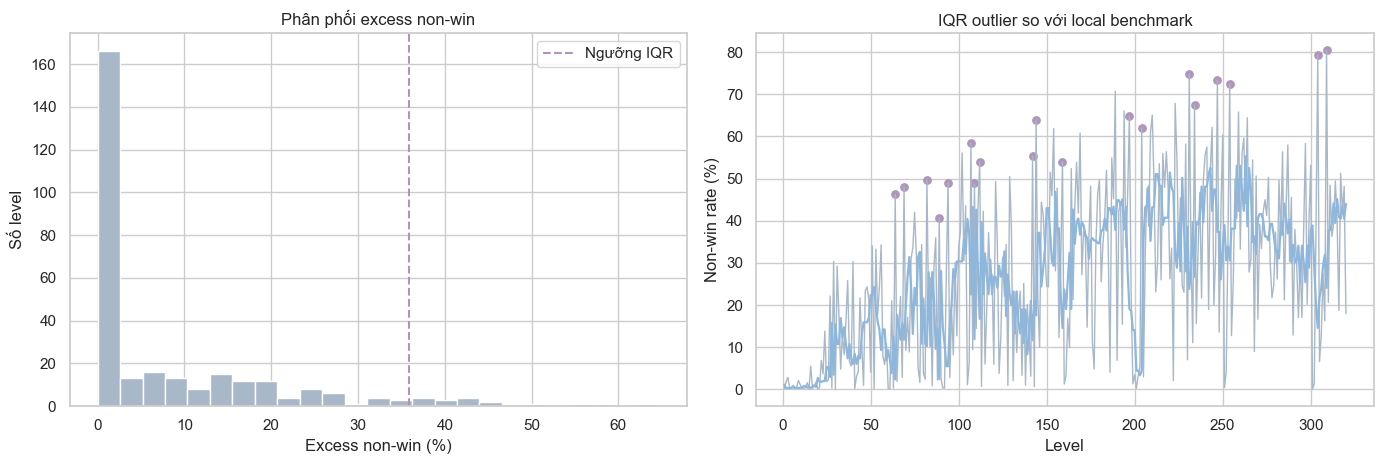

Độ nhạy của bước sàng lọc khi thay khoảng lân cận:


,Local window,IQR threshold,Số outlier
0,±2,36.6%,18
1,±4,35.9%,19
2,±6,37.0%,12


In [11]:
eligible_plot = analysis[analysis["is_eligible"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hist(eligible_plot["excess_non_win"] * 100, bins=25, color="#A8B8C9")
axes[0].axvline(
    iqr_threshold * 100, color="#B095BB", linestyle="--", label="Ngưỡng IQR"
)
axes[0].set(
    title="Phân phối excess non-win", xlabel="Excess non-win (%)", ylabel="Số level"
)
axes[0].legend()

shown = analysis[analysis.level_index <= 320]
axes[1].plot(shown.level_index, shown.non_win_rate * 100, color="#A8B8C9", lw=1)
axes[1].plot(
    shown.level_index, shown.local_non_win_median * 100, color="#8FB7DC", lw=1.6
)
spikes = shown[shown["is_iqr_outlier"]]
axes[1].scatter(spikes.level_index, spikes.non_win_rate * 100, color="#B095BB", s=28)
axes[1].set(
    title="IQR outlier so với local benchmark",
    xlabel="Level",
    ylabel="Non-win rate (%)",
)
plt.tight_layout()
plt.show()

# Giữ quy tắc IQR, thay khoảng lân cận để đánh giá độ nhạy.
sensitivity_rows = []
for radius in [2, 4, 6]:
    local_median = calculate_local_median(analysis, "non_win_rate", radius)
    excess = (analysis["non_win_rate"] - local_median).clip(lower=0)
    q1 = excess[analysis["is_eligible"]].quantile(0.25)
    q3 = excess[analysis["is_eligible"]].quantile(0.75)
    threshold = q3 + IQR_MULTIPLIER * (q3 - q1)
    column = f"iqr_radius_{radius}"
    analysis[column] = analysis["is_eligible"] & (excess > threshold)
    sensitivity_rows.append(
        {
            "Local window": f"±{radius}",
            "IQR threshold": threshold,
            "Số outlier": int(analysis[column].sum()),
        }
    )

analysis["iqr_windows_passed"] = analysis[
    ["iqr_radius_2", "iqr_radius_4", "iqr_radius_6"]
].sum(axis=1)
analysis["iqr_stable_all_windows"] = analysis["iqr_windows_passed"] == 3

sensitivity_summary = pd.DataFrame(sensitivity_rows)
print("Độ nhạy của bước sàng lọc khi thay khoảng lân cận:")
display(sensitivity_summary.style.format({"IQR threshold": "{:.1%}"}))


## 5. Đối chiếu hành vi tại 19 màn bất thường

Đối chiếu từng màn với mốc lân cận theo ba nhóm bằng chứng:

1. **Hành trình:** khả năng đi tiếp trong 24 giờ và quay lại ngày sau.
2. **Hành vi trong màn:** kết quả lần đầu, số lần chơi lại, item chưa giải quyết và mức sử dụng vật phẩm.
3. **Tính lặp lại:** hướng chênh lệch theo nền tảng và nhóm ngày tham gia.

Bước này phân biệt độ khó cao với độ khó đi kèm các dấu hiệu hành trình kém hơn.

Nhãn hành vi dùng hai ngưỡng trên tập màn đủ điều kiện: tỷ lệ thắng lần đầu thuộc nhóm 10% thấp nhất và tỷ lệ lượt có `attempt >= 5` thuộc nhóm 10% cao nhất. Một màn có thể thỏa cả hai điều kiện.


In [12]:
# Xác định ngưỡng hành vi từ tập màn đủ điều kiện.
eligible_behavior = analysis[analysis.is_eligible]
first_try_cutoff = eligible_behavior.first_attempt_win_rate.quantile(
    BEHAVIOR_PERCENTILE
)
retry_cutoff = eligible_behavior.attempt_5plus_share.quantile(1 - BEHAVIOR_PERCENTILE)

# Phân biệt khó ở lần đầu với chơi lại kéo dài.
low_first_try = analysis["first_attempt_win_rate"] <= first_try_cutoff
high_retry = analysis["attempt_5plus_share"] >= retry_cutoff

analysis["retry_pattern"] = "Không thuộc hai nhóm ngưỡng"
analysis.loc[low_first_try, "retry_pattern"] = "Tỷ lệ thắng lần đầu thấp"
analysis.loc[high_retry, "retry_pattern"] = "Nhiều lượt thử từ lần 5 trở lên"
analysis.loc[low_first_try & high_retry, "retry_pattern"] = (
    "Thắng lần đầu thấp và nhiều lượt thử từ lần 5"
)

candidate_impact = analysis[analysis.is_candidate][
    [
        "level_index",
        "start_users",
        "excess_non_win",
        "next_day_return_rate",
        "local_return_median",
        "retention_loss",
        "transition_excess",
    ]
].sort_values("retention_loss", ascending=False)
candidate_impact.style.format(
    {
        "start_users": "{:,.0f}",
        "excess_non_win": "+{:.1%}",
        "next_day_return_rate": "{:.1%}",
        "local_return_median": "{:.1%}",
        "retention_loss": "+{:.1%}",
        "transition_excess": "+{:.1%}",
    }
)


,level_index,start_users,excess_non_win,next_day_return_rate,local_return_median,retention_loss,transition_excess
143,144,"2,117",+46.4%,76.0%,77.1%,+1.1%,+9.2%
106,107,"2,759",+36.0%,70.9%,71.8%,+1.0%,+4.9%
108,109,"2,665",+36.9%,71.4%,72.2%,+0.7%,+4.6%
81,82,"3,388",+39.4%,71.2%,71.7%,+0.5%,+5.3%
253,254,721,+41.9%,86.4%,86.9%,+0.5%,+7.8%
230,231,926,+51.0%,82.3%,82.8%,+0.4%,+10.5%
93,94,"3,076",+43.5%,71.7%,72.1%,+0.4%,+4.4%
196,197,"1,219",+45.7%,81.0%,81.4%,+0.3%,+7.5%
158,159,"1,799",+39.4%,77.0%,77.2%,+0.3%,+4.1%
141,142,"2,121",+43.7%,76.1%,76.3%,+0.2%,+5.2%


In [13]:
candidate_behavior = analysis[analysis.is_candidate][
    [
        "level_index",
        "first_attempt_win_rate",
        "attempts_per_user",
        "attempt_5plus_share",
        "median_unsuccess_moves",
        "avg_unsolved_share",
        "booster_use_rate",
        "revive_use_rate",
        "retry_pattern",
    ]
].sort_values("attempt_5plus_share", ascending=False)
display(
    candidate_behavior.style.format(
        {
            "first_attempt_win_rate": "{:.1%}",
            "attempts_per_user": "{:.2f}",
            "attempt_5plus_share": "{:.1%}",
            "median_unsuccess_moves": "{:.0f}",
            "avg_unsolved_share": "{:.1%}",
            "booster_use_rate": "{:.1%}",
            "revive_use_rate": "{:.1%}",
        }
    )
)


,level_index,first_attempt_win_rate,attempts_per_user,attempt_5plus_share,median_unsuccess_moves,avg_unsolved_share,booster_use_rate,revive_use_rate,retry_pattern
308,309,14.7%,4.90,44.7%,20,96.9%,17.2%,54.7%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
303,304,21.2%,4.59,43.3%,8,96.4%,7.7%,41.6%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
246,247,40.5%,3.64,40.9%,18,92.2%,11.8%,42.1%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
230,231,31.0%,3.77,40.6%,12,97.6%,11.6%,36.4%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
253,254,31.4%,3.53,34.0%,13,92.2%,11.8%,43.9%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
196,197,50.9%,2.73,32.2%,17,86.9%,12.2%,37.5%,Nhiều lượt thử từ lần 5 trở lên
143,144,48.1%,2.69,28.5%,19,95.0%,9.8%,39.1%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
233,234,34.8%,3.00,27.8%,19,97.4%,14.3%,42.3%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
111,112,64.6%,2.14,23.4%,12,94.4%,6.8%,25.6%,Nhiều lượt thử từ lần 5 trở lên
203,204,42.0%,2.57,21.0%,16,98.3%,12.8%,42.9%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5


## 6. Tổng hợp bằng chứng để chọn ưu tiên

Mỗi màn bất thường được đánh giá bằng bốn điều kiện, không cộng thành một điểm tổng hợp:

- **Quay lại:** `retention_loss > 0` và không thấp hơn phân vị 75% của 19 màn bất thường.
- **Đi tiếp:** `transition_excess > 0`.
- **Lặp lại theo nhóm:** chênh lệch quay lại dương ở cả 2 nền tảng và ít nhất 2 nhóm ngày tham gia đủ mẫu.
- **Cỡ mẫu:** ít nhất 500 người đủ điều kiện đo tỷ lệ quay lại; mỗi nhóm đối chiếu cần ít nhất 100 người.

Phân vị 75% giữ các màn thuộc khoảng 25% có chênh lệch quay lại lớn nhất trong nhóm bất thường. Các ngưỡng cỡ mẫu và khoảng lân cận là quy ước sàng lọc của bài, không bảo đảm ý nghĩa thống kê. Kiểm tra độ nhạy theo khoảng lân cận được báo cáo riêng, không phải điều kiện thứ năm.


In [14]:
# Lấy phân vị 75% của chênh lệch quay lại trong tập màn bất thường.
candidate_retention = analysis[analysis["is_candidate"]]["retention_loss"]
retention_cutoff = candidate_retention.quantile(0.75)

analysis["pass_retention"] = (analysis["retention_loss"] >= retention_cutoff) & (
    analysis["retention_loss"] > 0
)
analysis["pass_transition"] = analysis["transition_excess"] > 0
analysis["pass_segment"] = analysis["retention_segment_confirmed"]
analysis["pass_sample"] = analysis["retention_eligible_users"] >= MIN_USERS

print(f"Ngưỡng chênh lệch quay lại để xét ưu tiên: {retention_cutoff:.2%}")
print(
    "Ngưỡng phân vị rút gọn danh sách điều tra; số màn ưu tiên phụ thuộc cả bốn điều kiện."
)
evidence_matrix = analysis[analysis.is_candidate][
    [
        "level_index",
        "excess_non_win",
        "retention_loss",
        "pass_retention",
        "transition_excess",
        "pass_transition",
        "pass_segment",
        "pass_sample",
    ]
].rename(
    columns={
        "excess_non_win": "Không thắng cao hơn lân cận",
        "retention_loss": "Quay lại thấp hơn lân cận",
        "pass_retention": "Đạt ngưỡng chênh lệch quay lại",
        "transition_excess": "Chưa đi tiếp cao hơn lân cận (tỷ lệ)",
        "pass_transition": "Chưa đi tiếp cao hơn lân cận",
        "pass_segment": "Lặp lại theo nhóm người chơi",
        "pass_sample": "Đủ mẫu",
    }
)
evidence_matrix.replace({True: "Có", False: "Không"}).sort_values(
    "Quay lại thấp hơn lân cận", ascending=False
).style.format(
    {
        "Không thắng cao hơn lân cận": "+{:.1%}",
        "Quay lại thấp hơn lân cận": "+{:.1%}",
        "Chưa đi tiếp cao hơn lân cận (tỷ lệ)": "+{:.1%}",
    }
)


Ngưỡng chênh lệch quay lại để xét ưu tiên: 0.44%
Ngưỡng phân vị rút gọn danh sách điều tra; số màn ưu tiên phụ thuộc cả bốn điều kiện.


,level_index,Không thắng cao hơn lân cận,Quay lại thấp hơn lân cận,Đạt ngưỡng chênh lệch quay lại,Chưa đi tiếp cao hơn lân cận (tỷ lệ),Chưa đi tiếp cao hơn lân cận,Lặp lại theo nhóm người chơi,Đủ mẫu
143,144,+46.4%,+1.1%,Có,+9.2%,Có,Có,Có
106,107,+36.0%,+1.0%,Có,+4.9%,Có,Có,Có
108,109,+36.9%,+0.7%,Có,+4.6%,Có,Có,Có
81,82,+39.4%,+0.5%,Có,+5.3%,Có,Không,Có
253,254,+41.9%,+0.5%,Có,+7.8%,Có,Không,Có
230,231,+51.0%,+0.4%,Không,+10.5%,Có,Không,Có
93,94,+43.5%,+0.4%,Không,+4.4%,Có,Không,Có
196,197,+45.7%,+0.3%,Không,+7.5%,Có,Không,Có
158,159,+39.4%,+0.3%,Không,+4.1%,Có,Không,Có
141,142,+43.7%,+0.2%,Không,+5.2%,Có,Không,Có


## 7. Nhóm ưu tiên và nhóm theo dõi

Nhóm ưu tiên (`Priority`) gồm các màn bất thường thỏa đồng thời bốn điều kiện ở phần 6. Nhóm theo dõi (`Watchlist`) gồm các màn bất thường còn lại. Việc chưa được ưu tiên không có nghĩa màn đó không khó; bằng chứng hiện tại chưa thỏa quy tắc điều tra đã chọn.


In [15]:
analysis["is_priority"] = (
    analysis["is_candidate"]
    & analysis["pass_retention"]
    & analysis["pass_transition"]
    & analysis["pass_segment"]
    & analysis["pass_sample"]
)

priority_levels = (
    analysis[analysis.is_priority]
    .sort_values("retention_loss", ascending=False)["level_index"]
    .astype(int)
    .tolist()
)
watchlist_levels = (
    analysis[analysis["is_candidate"] & ~analysis["is_priority"]]
    .sort_values("retention_loss", ascending=False)["level_index"]
    .astype(int)
    .tolist()
)

analysis["decision"] = "Not selected"
analysis.loc[analysis.is_candidate, "decision"] = "Watchlist"
analysis.loc[analysis.is_priority, "decision"] = "Priority"

print("Priority:", priority_levels)
print("Số level Watchlist:", len(watchlist_levels))
print("Watchlist:", watchlist_levels)

selection = analysis[analysis.is_candidate][
    [
        "level_index",
        "decision",
        "start_users",
        "excess_non_win",
        "retention_loss",
        "transition_excess",
        "retention_segment_confirmed",
        "iqr_windows_passed",
    ]
].sort_values(["decision", "retention_loss"], ascending=[True, False])
selection.replace({True: "Có", False: "Không"}).style.format(
    {
        "start_users": "{:,.0f}",
        "excess_non_win": "+{:.1%}",
        "retention_loss": "+{:.1%}",
        "transition_excess": "+{:.1%}",
    }
)


Priority: [144, 107, 109]
Số level Watchlist: 16
Watchlist: [82, 254, 231, 94, 197, 159, 142, 247, 69, 112, 64, 309, 304, 89, 204, 234]


,level_index,decision,start_users,excess_non_win,retention_loss,transition_excess,retention_segment_confirmed,iqr_windows_passed
143,144,Priority,"2,117",+46.4%,+1.1%,+9.2%,Có,3
106,107,Priority,"2,759",+36.0%,+1.0%,+4.9%,Có,2
108,109,Priority,"2,665",+36.9%,+0.7%,+4.6%,Có,1
81,82,Watchlist,"3,388",+39.4%,+0.5%,+5.3%,Không,3
253,254,Watchlist,721,+41.9%,+0.5%,+7.8%,Không,3
230,231,Watchlist,926,+51.0%,+0.4%,+10.5%,Không,3
93,94,Watchlist,"3,076",+43.5%,+0.4%,+4.4%,Không,3
196,197,Watchlist,"1,219",+45.7%,+0.3%,+7.5%,Không,3
158,159,Watchlist,"1,799",+39.4%,+0.3%,+4.1%,Không,2
141,142,Watchlist,"2,121",+43.7%,+0.2%,+5.2%,Không,3


## 8. Phân tích màn ưu tiên và trường hợp màn 109

Các bảng đầu đối chiếu hành vi ở nhóm ưu tiên. Phần tiếp theo đọc bảng tổng hợp cho hai nhóm có và không dùng vật phẩm ở lần đầu gặp màn 109.

Tỷ lệ trong bảng màn 109 được lưu ở mức làm tròn 0,1 điểm phần trăm; doanh thu làm tròn tới 0,01 USD. Hai nhóm tự chọn nên chênh lệch không chứng minh tác động của vật phẩm.


In [16]:
deep_dive_1 = analysis[analysis.level_index.isin(priority_levels)][
    [
        "level_index",
        "attempt_win_rate",
        "first_attempt_win_rate",
        "attempts_per_user",
        "attempt_5plus_share",
        "median_win_time",
        "excess_non_win",
        "retry_pattern",
    ]
].sort_values("attempt_win_rate")
display(
    deep_dive_1.style.format(
        {
            "attempt_win_rate": "{:.1%}",
            "first_attempt_win_rate": "{:.1%}",
            "attempts_per_user": "{:.2f}",
            "attempt_5plus_share": "{:.1%}",
            "median_win_time": "{:.0f}s",
            "excess_non_win": "+{:.1%}",
        }
    )
)

deep_dive_2 = analysis[analysis.level_index.isin(priority_levels)][
    [
        "level_index",
        "avg_unsolved_share",
        "local_avg_unsolved_share",
        "median_unsuccess_moves",
        "local_median_unsuccess_moves",
        "booster_use_rate",
        "local_booster_use_rate",
        "revive_use_rate",
        "local_revive_use_rate",
    ]
].sort_values("avg_unsolved_share", ascending=False)
display(
    deep_dive_2.style.format(
        {
            "avg_unsolved_share": "{:.1%}",
            "local_avg_unsolved_share": "{:.1%}",
            "median_unsuccess_moves": "{:.0f}",
            "local_median_unsuccess_moves": "{:.0f}",
            "booster_use_rate": "{:.1%}",
            "local_booster_use_rate": "{:.1%}",
            "revive_use_rate": "{:.1%}",
            "local_revive_use_rate": "{:.1%}",
        }
    )
)

# Dùng các chỉ số theo nhóm đã tính ở phần 3.
deep_dive_3 = analysis[analysis.level_index.isin(priority_levels)][
    [
        "level_index",
        "start_users",
        "next_day_return_rate",
        "local_return_median",
        "retention_loss",
        "transition_excess",
        "retention_platform_confirmed",
        "retention_cohort_confirmed",
        "retention_segment_confirmed",
        "iqr_windows_passed",
    ]
].sort_values("retention_loss", ascending=False)
deep_dive_3.replace({True: "Có", False: "Không"}).style.format(
    {
        "start_users": "{:,.0f}",
        "next_day_return_rate": "{:.1%}",
        "local_return_median": "{:.1%}",
        "retention_loss": "+{:.1%}",
        "transition_excess": "+{:.1%}",
    }
)


,level_index,attempt_win_rate,first_attempt_win_rate,attempts_per_user,attempt_5plus_share,median_win_time,excess_non_win,retry_pattern
143,144,36.0%,48.1%,2.69,28.5%,216s,+46.4%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
106,107,41.5%,47.5%,2.35,18.8%,129s,+36.0%,Thắng lần đầu thấp và nhiều lượt thử từ lần 5
108,109,51.2%,61.9%,1.91,14.3%,142s,+36.9%,Không thuộc hai nhóm ngưỡng


,level_index,avg_unsolved_share,local_avg_unsolved_share,median_unsuccess_moves,local_median_unsuccess_moves,booster_use_rate,local_booster_use_rate,revive_use_rate,local_revive_use_rate
106,107,95.2%,88.4%,11,18,7.0%,4.6%,28.7%,21.4%
143,144,95.0%,89.6%,19,16,9.8%,2.6%,39.1%,19.1%
108,109,90.2%,86.6%,19,16,8.5%,3.4%,33.3%,15.0%


,level_index,start_users,next_day_return_rate,local_return_median,retention_loss,transition_excess,retention_platform_confirmed,retention_cohort_confirmed,retention_segment_confirmed,iqr_windows_passed
143,144,"2,117",76.0%,77.1%,+1.1%,+9.2%,Có,Có,Có,3
106,107,"2,759",70.9%,71.8%,+1.0%,+4.9%,Có,Có,Có,2
108,109,"2,665",71.4%,72.2%,+0.7%,+4.6%,Có,Có,Có,1


In [17]:
# Bảng local chứa số liệu tổng hợp của hai nhóm, không chứa ID người chơi.
resource_any_109 = load_data("level_109_resource_summary.csv")
assert set(resource_any_109["resource_any_group"]) == {"No resource", "Any resource"}
print(f"Màn 109: {int(resource_any_109['users'].sum()):,} người trong hai nhóm")
display(
    resource_any_109.style.format(
        {
            "users": "{:,.0f}",
            "first_attempt_win": "{:.1%}",
            "transition_24h": "{:.1%}",
            "next_day_return": "{:.1%}",
            "payer_rate_24h": "{:.1%}",
            "iap_revenue_per_user_24h": "${:.2f}",
        }
    )
)


Màn 109: 2,623 người trong hai nhóm


,resource_any_group,users,first_attempt_win,transition_24h,next_day_return,payer_rate_24h,iap_revenue_per_user_24h
0,Any resource,"1,133",79.2%,95.2%,71.3%,4.2%,$0.54
1,No resource,"1,490",45.6%,90.3%,72.9%,1.9%,$0.19


## 9. Kết luận và hướng điều tra

Bảng dưới đây tổng hợp bằng chứng và hướng kiểm tra cho ba màn ưu tiên.


In [18]:
# Lưu bảng chỉ số đã tính ở các phần trước.
analysis.to_csv("output/level_analysis_master.csv", index=False)

# Diễn giải từng màn dựa trên các bảng đối chiếu ở phần 8.
recommendations = pd.DataFrame(
    [
        {
            "level_index": 107,
            "Nhận định": "Tỷ lệ thắng lần đầu thấp; số bước khi không thắng thấp hơn lân cận.",
            "Hướng kiểm tra": "Xem bản ghi lần chơi đầu và kiểm tra phần mở đầu, mục tiêu màn chơi.",
        },
        {
            "level_index": 109,
            "Nhận định": "Nhóm dùng vật phẩm đi tiếp và trả tiền nhiều hơn, nhưng quay lại ngày sau ít hơn.",
            "Hướng kiểm tra": "Đối chiếu nguồn vật phẩm và lịch sử trả tiền trước khi đề xuất điều chỉnh.",
        },
        {
            "level_index": 144,
            "Nhận định": "Tỷ lệ không thắng, chơi lại và chưa đi tiếp cùng cao hơn lân cận.",
            "Hướng kiểm tra": "Xem bản ghi lượt chơi và cấu hình để xác định điểm gây khó.",
        },
    ]
)

priority_summary = analysis.loc[
    analysis["is_priority"],
    ["level_index", "excess_non_win", "transition_excess", "retention_loss"],
].merge(recommendations, on="level_index", how="left", validate="one_to_one")
priority_summary = priority_summary.sort_values("retention_loss", ascending=False)

# Đổi chênh lệch tỷ lệ sang điểm phần trăm để dễ đọc.
difference_columns = ["excess_non_win", "transition_excess", "retention_loss"]
priority_summary[difference_columns] = priority_summary[difference_columns] * 100
print(
    f"Trong {int(analysis['is_eligible'].sum())} màn đủ mẫu, "
    f"có {int(analysis['is_candidate'].sum())} màn bất thường "
    f"và {len(priority_summary)} màn được ưu tiên điều tra."
)
print("Chưa có cơ sở để giảm độ khó đồng loạt.")
display(
    priority_summary.style.format(
        {column: "{:+.1f}" for column in difference_columns}
    ).relabel_index(
        ["Màn", "Không thắng tăng (điểm %)", "Chưa đi tiếp tăng (điểm %)",
         "Quay lại giảm (điểm %)", "Nhận định", "Hướng kiểm tra"],
        axis="columns",
    )
)


Trong 298 màn đủ mẫu, có 19 màn bất thường và 3 màn được ưu tiên điều tra.
Chưa có cơ sở để giảm độ khó đồng loạt.


,Màn,Không thắng tăng (điểm %),Chưa đi tiếp tăng (điểm %),Quay lại giảm (điểm %),Nhận định,Hướng kiểm tra
2,144,+46.4,+9.2,+1.1,"Tỷ lệ không thắng, chơi lại và chưa đi tiếp cùng cao hơn lân cận.",Xem bản ghi lượt chơi và cấu hình để xác định điểm gây khó.
0,107,+36.0,+4.9,+1.0,Tỷ lệ thắng lần đầu thấp; số bước khi không thắng thấp hơn lân cận.,"Xem bản ghi lần chơi đầu và kiểm tra phần mở đầu, mục tiêu màn chơi."
1,109,+36.9,+4.6,+0.7,"Nhóm dùng vật phẩm đi tiếp và trả tiền nhiều hơn, nhưng quay lại ngày sau ít hơn.",Đối chiếu nguồn vật phẩm và lịch sử trả tiền trước khi đề xuất điều chỉnh.


# Phụ lục: SQL tham khảo

[Các truy vấn kiểm tra và tổng hợp dữ liệu](sql/).
